# evaluación y transferencia: Métodos y evidencia

**Nivel:** 1 **Requisitos previos:** 01–04 en orden **Tiempo de lectura:** 15 minutos

**Pregunta:** ¿Qué puede establecer una traza C01 emparejada y qué requiere los denominadores completos de núcleo y transferencia?

## Objetivos

Esta lección investiga la pregunta: ¿Qué puede establecer una traza C01 emparejada y qué requiere los denominadores completos de núcleo y transferencia?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/research.json` - `data/derived/semantic-transfer/index.json` - `data/derived/semantic-transfer/report.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M04-C01-nominal-40000; - `data/derived/episodes/M09-C01-nominal-40000; - `data/derived/episodes/M12-C01-nominal-40000; json`

## Método

Reconstruye cómo una afirmación científica depende de la identidad de las trazas, los denominadores, las familias de tareas y las particiones de transferencia. Una ejecución por caso ilustra un método; las conclusiones de fiabilidad dependen de la matriz auditada completa y siguen limitadas a sus tareas diseñadas. En el ejercicio de una ejecución de evaluación y transferencia para C01, el índice de episodios sirve para auditoría, no define por sí solo la unidad inferencial; En el ejercicio de una ejecución de evaluación y transferencia para C01, familia, variante y semilla determinan qué resultados son independientes y cuáles comparten entorno. En el ejercicio de una ejecución de evaluación y transferencia para C01, incluye todos los intentos en el denominador, conserva fallos y separa casos centrales de composiciones retenidas antes de calcular éxito o intervalos de confianza.

### evaluación y transferencia · nivel 1 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Carga las trazas propias y verifica sus hashes; nunca modifica los artefactos canónicos.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M04", "M09", "M12"]
trace_methods = ["M01", "M04", "M09", "M12"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Trazas verificadas por hash:", len(records))


Trazas verificadas por hash: 4


### evaluación y transferencia · L1 | Construir la primera política ejecutable

Construye M01 para evaluación y transferencia con la fábrica pública y conserva su contrato de observación antes de muestrear C01

In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M01


### evaluación y transferencia · L1 | Ejecutar el método principal en el caso indicado

De evaluación y transferencia, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida

In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### evaluación y transferencia · L1 | Construir una política de comparación independiente

Crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación

In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M02


### evaluación y transferencia · L1 | Ejecutar la comparación bajo condiciones idénticas

Dentro de esta ejecución de evaluación y transferencia (C01), esta comparación de nivel 1 ejecuta M02 en el mismo C01, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### evaluación y transferencia · L1 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de evaluación y transferencia, y las afirmaciones entre familias aún requieren el benchmark completo

In [7]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### evaluación y transferencia · L1 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de evaluación y transferencia recién ejecutados en C01, no se copia de un artefacto congelado

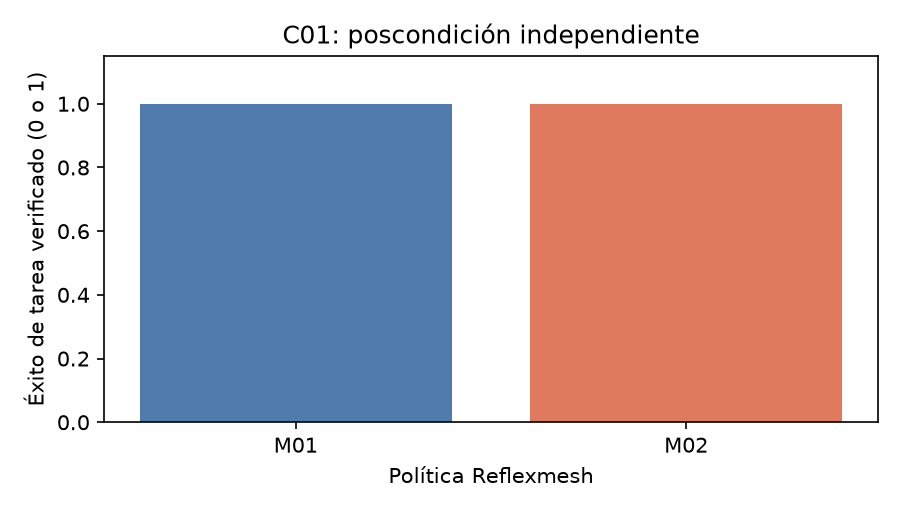

In [8]:
# Grafica los resultados verificados independientemente de las dos ejecuciones nuevas.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Éxito de tarea verificado (0 o 1)")
ax.set_xlabel("Política Reflexmesh")
ax.set_title(f"{sample_case}: poscondición independiente")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para evaluación y transferencia, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C01; Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En el ejercicio de una ejecución de evaluación y transferencia para C01, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

## Resultados

**Respuesta:** El ejemplo de evaluación y transferencia ejecuta 2 políticas, M01 y M02, en C01; En el ejemplo de evaluación y transferencia con C01, la muestra emparejada demuestra la API y la verificación independiente, no el rendimiento del benchmark.

La matriz central está saturada: Siete métodos resuelven los 1; Dentro de esta ejecución de evaluación y transferencia (C01), 200 episodios y solo 71/1.440 celdas método/caso/variante cambian por semilla; En transferencia estructural, M04 resuelve 24/24 casos y M12 21/24; Dentro de esta ejecución de evaluación y transferencia (C01), el carril semántico opaco mayor también favorece M09 frente a M12; No hay respaldo para afirmar superioridad aprendida;

En el ejercicio de una ejecución de evaluación y transferencia para C01, este paso de autoría no compromete salidas generadas; `scripts/run_notebooks; py` las ejecuta y guarda desde un kernel nuevo.

## Resumen

Dentro de esta ejecución de evaluación y transferencia (C01), este ejemplo de evaluación y transferencia usa C01 para mostrar el comportamiento bajo una condición declarada. En el ejercicio de una ejecución de evaluación y transferencia para C01, mantén el resultado medido separado de afirmaciones sobre inteligencia general para controlar software.



## Referencias
- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682) - [SWE](https://arxiv.org/abs/2310.06770) - [TAU2](https://arxiv.org/abs/2506.07982)